In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [2]:
df_path = "/content/drive/MyDrive/Model/Data sebelum imputasi/Data konsentrasi perjam DKI5 Kebon Jeruk.xlsx"
df = pd.read_excel(df_path)
df = df.replace('---', np.nan)
pollutant_cols = ['PM10', 'PM2.5', 'SO2', 'CO', 'O3', 'NO', 'NO2', 'NOX']
df[pollutant_cols] = df[pollutant_cols].replace(0, np.nan)
df.head(10)

/tmp/ipykernel_3671/2431711254.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('---', np.nan)


,datetime,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
0,2020-01-01 00:00:00,44.91,NaN,21.87,1.44,73.55,3.04,13.33,8.76,25.010000,0.54,23.940001,93.800003,0.575,0.000000
1,2020-01-01 01:00:00,52.26,NaN,20.67,1.12,89.50,1.66,5.93,2.67,25.110001,0.50,23.959999,93.349998,0.801,0.000000
2,2020-01-01 02:00:00,50.9,NaN,20.37,1.05,78.54,1.22,0.16,0.78,25.379999,0.45,23.209999,87.800003,1.323,0.000000
3,2020-01-01 03:00:00,48.44,NaN,20.05,1.02,85.28,1.13,NaN,0.20,25.330000,0.54,23.170000,87.849998,1.757,0.000000
4,2020-01-01 04:00:00,45.65,NaN,19.91,1.00,84.65,1.10,NaN,NaN,25.420000,0.87,23.320000,88.180000,1.945,0.000000
5,2020-01-01 05:00:00,39.52,NaN,20.14,1.01,79.43,1.23,NaN,0.69,26.309999,1.56,23.389999,84.000000,2.575,0.000000
6,2020-01-01 06:00:00,33.35,NaN,20.18,1.00,77.74,1.14,NaN,0.26,26.459999,1.90,23.299999,82.809998,1.836,35.840000
7,2020-01-01 07:00:00,23.4,NaN,20.08,1.04,74.29,1.65,3.12,2.75,26.389999,1.21,23.549999,84.419998,1.437,101.919998
8,2020-01-01 08:00:00,19.31,NaN,19.88,1.22,85.43,2.83,11.06,7.49,26.900000,0.96,23.230000,80.349998,1.373,148.770004
9,2020-01-01 09:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.000000,0.63,23.110001,79.309998,1.320,198.160004


In [3]:
for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')
print(df.dtypes)

datetime                   datetime64[ns]
PM10                              float64
PM2.5                             float64
SO2                               float64
CO                                float64
O3                                float64
NO                                float64
NO2                               float64
NOX                               float64
Suhu Udara (°C)                   float64
Curah Hujan (mm)                  float64
Suhu Titik Embun (°C)             float64
Kelembaban Relatif (%)            float64
Kecepatan Angin (m/s)             float64
Radiasi Matahari (W/m²)           float64
dtype: object


In [4]:
df.isnull().sum()

,0
datetime,0
PM10,2581
PM2.5,9488
SO2,3193
CO,783
O3,788
NO,1398
NO2,2523
NOX,1499
Suhu Udara (°C),0


In [5]:
missing_percent = df.isnull().mean() * 100
missing_percent_str = missing_percent.round(2).astype(str) + ' %'
(missing_percent.round(2)).astype(str) + ' %'

,0
datetime,0.0 %
PM10,5.89 %
PM2.5,21.64 %
SO2,7.28 %
CO,1.79 %
O3,1.8 %
NO,3.19 %
NO2,5.75 %
NOX,3.42 %
Suhu Udara (°C),0.0 %


In [6]:
df_numeric = df.select_dtypes(include='number')
df_numeric.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,41267.00,34360.00,40655.00,43065.00,43060.00,42450.00,41325.00,42349.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,50.34,39.48,28.90,1.19,84.37,11.88,26.23,21.25,26.90,0.33,23.17,81.14,1.54,210.66
std,25.05,24.33,11.72,0.86,62.94,18.24,21.31,20.89,2.62,1.07,1.04,11.71,0.85,283.35
min,0.91,0.09,0.07,0.01,0.03,0.01,0.01,0.01,20.42,0.00,16.58,35.23,0.01,0.00
25%,32.00,21.92,21.37,0.65,31.72,2.27,11.26,8.16,24.72,0.00,22.64,72.73,0.95,0.00
50%,46.82,35.53,27.58,1.07,72.62,4.41,21.34,15.16,26.28,0.03,23.26,84.31,1.36,12.57
75%,64.00,51.47,35.09,1.51,122.70,15.35,35.53,26.84,29.00,0.19,23.85,90.94,1.99,419.22
max,516.94,243.55,265.18,54.61,451.26,236.22,240.04,273.21,35.78,32.71,26.68,98.86,6.39,1059.79


In [7]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

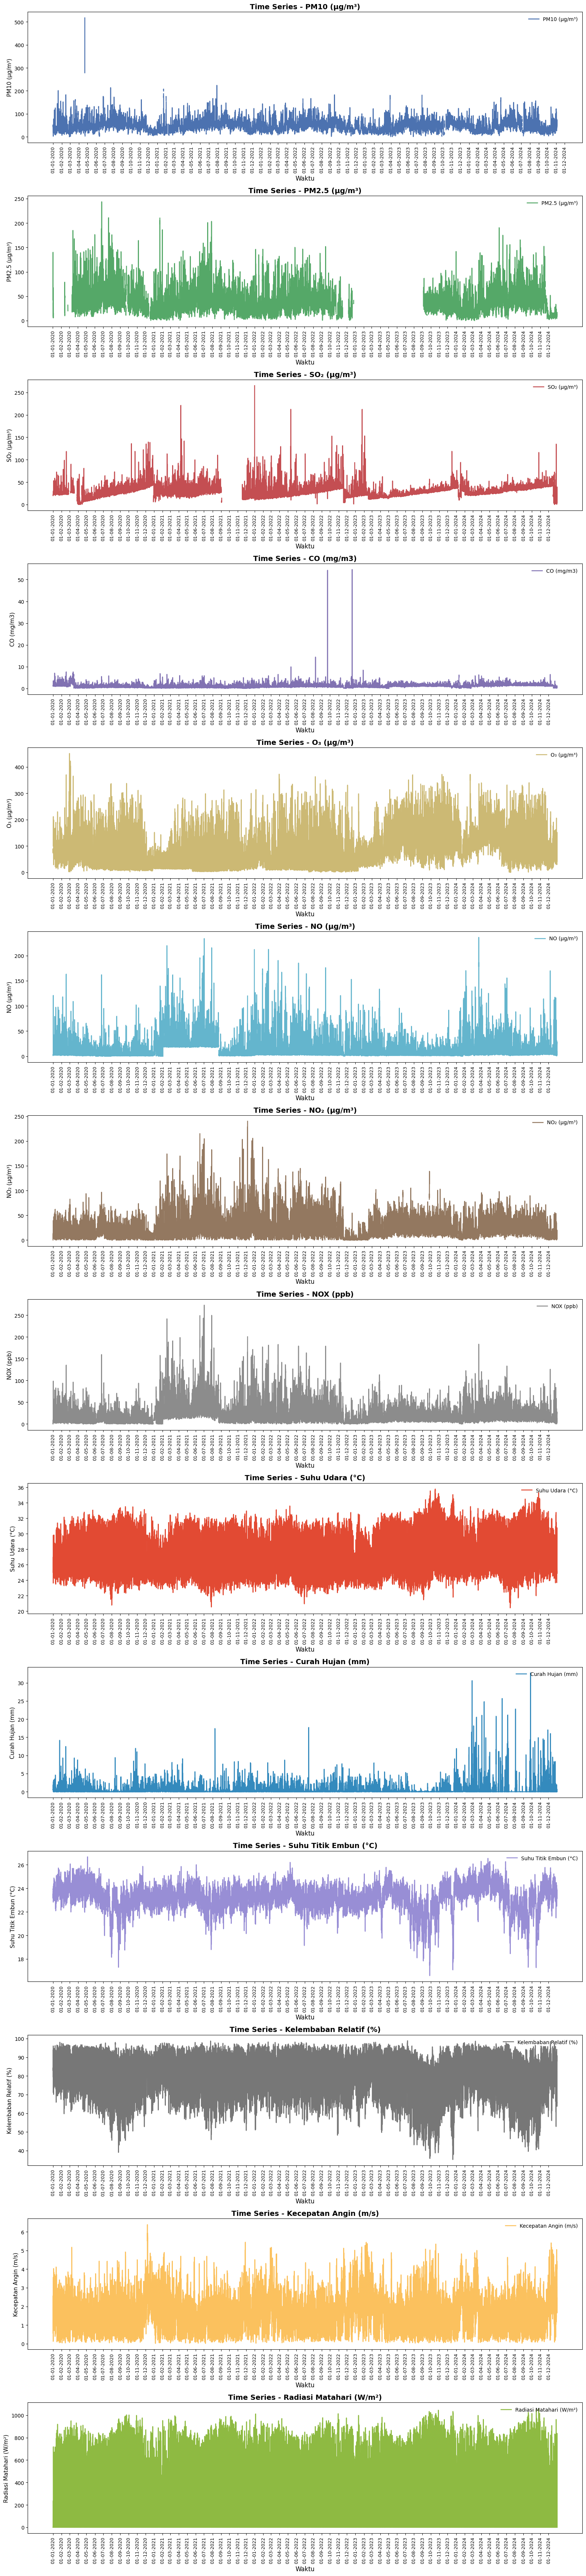

In [8]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)

df_ts = df_ts.sort_index()
hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)
xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]


xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()

In [9]:
df['datetime'] = pd.to_datetime(df['datetime'])
datetime_index = df['datetime']
numeric_cols = df.select_dtypes(include=[np.number]).columns
df_numeric = df[numeric_cols]

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)

In [10]:
imputer = KNNImputer(n_neighbors=5)
df_imputed_scaled = imputer.fit_transform(df_scaled)

In [11]:
df_imputed_numeric = pd.DataFrame(
    scaler.inverse_transform(df_imputed_scaled),
    columns=numeric_cols
)

In [12]:
df_imputed = df_imputed_numeric.copy()
df_imputed.index = datetime_index
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
datetime,,,,,,,,,,,,,,
2020-01-01 00:00:00,44.910,33.192,21.870,1.440,73.55,3.040,13.330,8.760,25.010000,0.54,23.940001,93.800003,0.575,0.000000
2020-01-01 01:00:00,52.260,35.508,20.670,1.120,89.50,1.660,5.930,2.670,25.110001,0.50,23.959999,93.349998,0.801,0.000000
2020-01-01 02:00:00,50.900,36.126,20.370,1.050,78.54,1.220,0.160,0.780,25.379999,0.45,23.209999,87.800003,1.323,0.000000
2020-01-01 03:00:00,48.440,32.750,20.050,1.020,85.28,1.130,8.706,0.200,25.330000,0.54,23.170000,87.849998,1.757,0.000000
2020-01-01 04:00:00,45.650,39.614,19.910,1.000,84.65,1.100,14.926,9.072,25.420000,0.87,23.320000,88.180000,1.945,0.000000
2020-01-01 05:00:00,39.520,12.222,20.140,1.010,79.43,1.230,12.164,0.690,26.309999,1.56,23.389999,84.000000,2.575,0.000000
2020-01-01 06:00:00,33.350,31.378,20.180,1.000,77.74,1.140,6.288,0.260,26.459999,1.90,23.299999,82.809998,1.836,35.840000
2020-01-01 07:00:00,23.400,12.086,20.080,1.040,74.29,1.650,3.120,2.750,26.389999,1.21,23.549999,84.419998,1.437,101.919998
2020-01-01 08:00:00,19.310,21.292,19.880,1.220,85.43,2.830,11.060,7.490,26.900000,0.96,23.230000,80.349998,1.373,148.770004


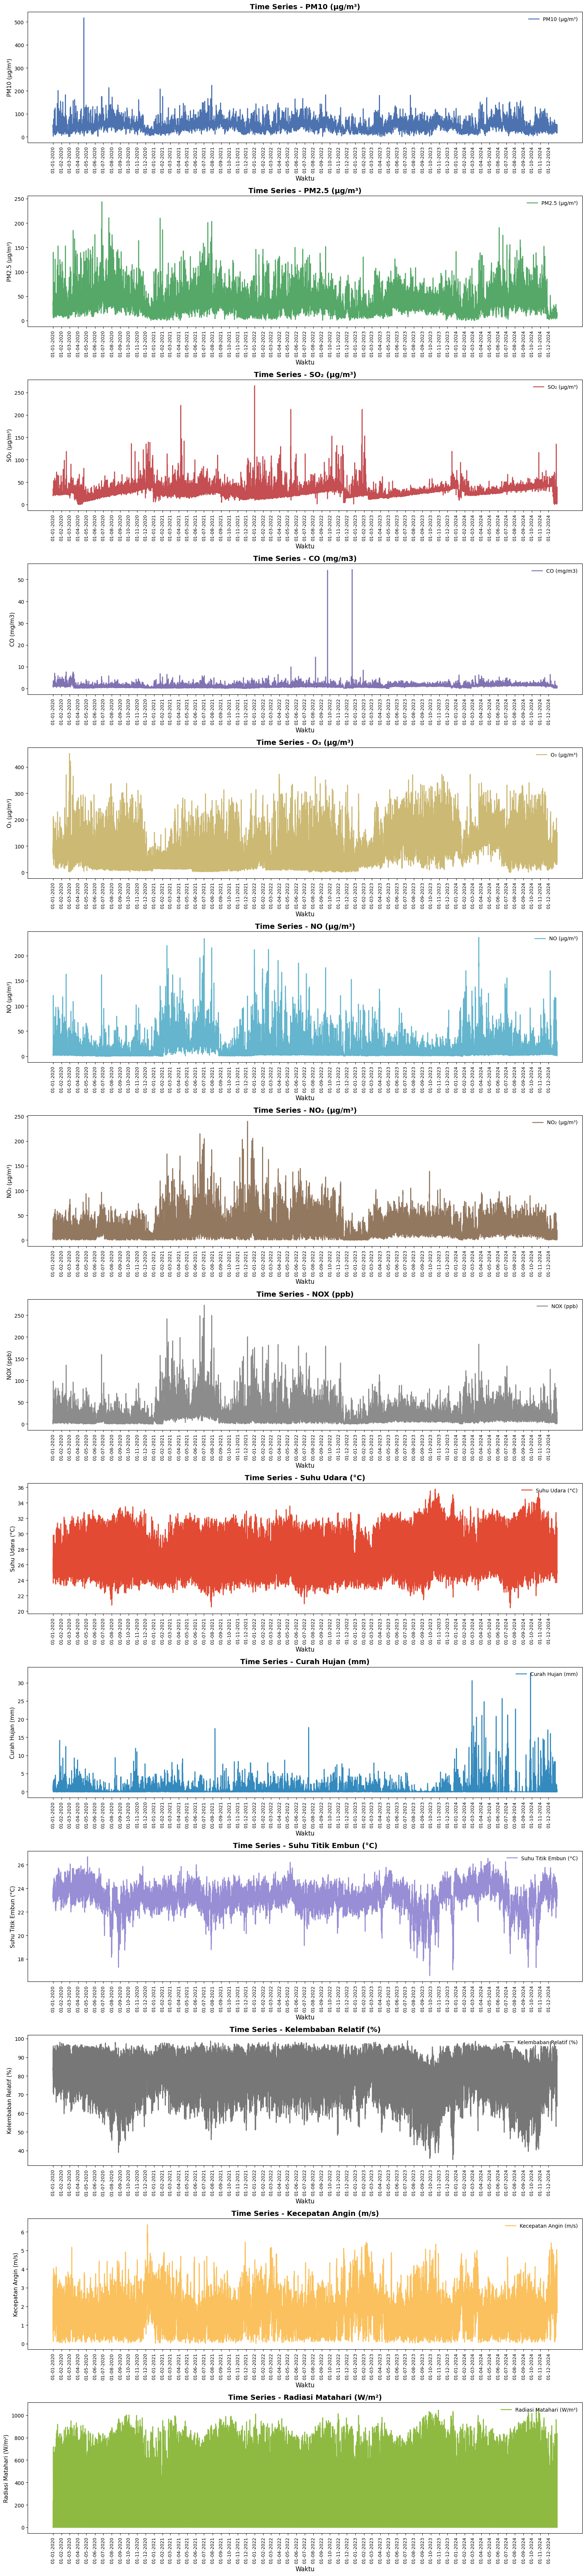

In [13]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)

df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(),
                       freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()

In [14]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,49.96,38.31,28.82,1.19,84.44,11.80,25.56,21.05,26.90,0.33,23.17,81.14,1.54,210.66
std,24.74,23.23,11.46,0.85,62.80,18.04,21.12,20.70,2.62,1.07,1.04,11.71,0.85,283.35
min,0.91,0.09,0.07,0.01,0.03,0.01,0.01,0.01,20.42,0.00,16.58,35.23,0.01,0.00
25%,31.90,21.50,21.50,0.65,32.03,2.28,10.56,8.08,24.72,0.00,22.64,72.73,0.95,0.00
50%,46.30,34.68,27.59,1.06,72.69,4.46,20.68,15.01,26.28,0.03,23.26,84.31,1.36,12.57
75%,63.44,49.79,34.80,1.51,122.81,15.12,34.79,26.65,29.00,0.19,23.85,90.94,1.99,419.22
max,516.94,243.55,265.18,54.61,451.26,236.22,240.04,273.21,35.78,32.71,26.68,98.86,6.39,1059.79


In [15]:
df_imputed.loc[:, ~df_imputed.columns.isin(['NO', 'NOX'])].describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,49.96,38.31,28.82,1.19,84.44,25.56,26.90,0.33,23.17,81.14,1.54,210.66
std,24.74,23.23,11.46,0.85,62.80,21.12,2.62,1.07,1.04,11.71,0.85,283.35
min,0.91,0.09,0.07,0.01,0.03,0.01,20.42,0.00,16.58,35.23,0.01,0.00
25%,31.90,21.50,21.50,0.65,32.03,10.56,24.72,0.00,22.64,72.73,0.95,0.00
50%,46.30,34.68,27.59,1.06,72.69,20.68,26.28,0.03,23.26,84.31,1.36,12.57
75%,63.44,49.79,34.80,1.51,122.81,34.79,29.00,0.19,23.85,90.94,1.99,419.22
max,516.94,243.55,265.18,54.61,451.26,240.04,35.78,32.71,26.68,98.86,6.39,1059.79


In [ ]:
df_imputed['datetime'] = df_imputed.index
df_imputed.to_excel("/content/drive/MyDrive/Model/Data Imputasi/df_imputed.xlsx", index=False)